# Does a transformer that sees neighbouring epochs beat per-epoch sleep classifiers?

Sleep staging from an Apple Watch (Walch et al. 2019, PhysioNet `sleep-accel`): 31 subjects,
one lab night each, accelerometer and PPG heart rate scored against polysomnography (PSG).

**Question.** With the paper's three features (activity counts, HR standard deviation, a clock
proxy) and subject-wise evaluation, does a small transformer encoder that sees a window of
neighbouring 30 s epochs beat the paper's four per-epoch classifiers (logistic regression,
k-NN, random forest, MLP)?

**Short answer.**
- **Wake / NREM / REM: yes.** The transformer's κ is higher than every paper model's, and every
  paired difference has a 95% CI above zero.
- **Wake / sleep: no** on κ or macro-F1 (a tie), but it ranks epochs better (higher AUC).

This notebook only reads the files in `results/tables/` and `results/figures/`, written by
`make eval`. It trains nothing.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TABLES, FIGURES = ROOT / "results" / "tables", ROOT / "results" / "figures"
NAMES = {"baseline": "majority baseline", "logreg": "logistic regression", "knn": "k-NN",
         "rf": "random forest", "mlp": "MLP", "transformer": "transformer (3 seeds)"}
PAPER = ["logreg", "knn", "rf", "mlp"]
pd.set_option("display.max_colwidth", None)


def with_ci(df: pd.DataFrame, metrics: list[str]) -> pd.DataFrame:
    """'mean [lo, hi]' strings for each metric, one row per model."""
    out = pd.DataFrame(index=df["model"].map(NAMES))
    for m in metrics:
        out[m] = [f"{r[m]:.3f} [{r[m + '_lo']:.3f}, {r[m + '_hi']:.3f}]" if pd.notna(r[m]) else "n/a"
                  for _, r in df.iterrows()]
    return out.rename_axis(None)

## 1. Data

- 31 subjects, one in-lab PSG night each, 30 s epochs.
- Epochs are kept if they lie inside the window where PSG, accelerometer and heart rate all
  have data, are scored (stage codes 0–5), and contain accelerometer samples (the reference
  code's rule).
- Labels: **2-class** Wake / Sleep; **3-class** Wake / NREM / REM. Stage code 4 (R&K stage 4,
  present in three nights) counts as sleep / NREM.

In [2]:
subjects = pd.read_csv(TABLES / "subjects.csv", dtype={"subject": str})
stages = subjects[["n_W", "n_N1", "n_N2", "n_N3", "n_N4", "n_REM"]].sum()
print(f"{len(subjects)} subjects, {subjects['kept'].sum():,} epochs kept "
      f"({subjects['unscored'].sum()} unscored and {subjects['no_motion'].sum():,} no-motion epochs dropped)")
print(f"epochs per subject: median {subjects['kept'].median():.0f}, range {subjects['kept'].min()}–{subjects['kept'].max()}")
(stages / stages.sum()).rename(lambda c: c[2:]).to_frame("share of kept epochs").T.round(3)

31 subjects, 25,548 epochs kept (438 unscored and 1,240 no-motion epochs dropped)
epochs per subject: median 938, range 119–980


,W,N1,N2,N3,N4,REM
share of kept epochs,0.085,0.069,0.489,0.125,0.014,0.218


- The classes are imbalanced: wake is about a tenth of the epochs, so accuracy alone says
  little. The majority baseline (always "sleep" / always "NREM") is shown beside every result.
- Subject 7749105 keeps only 119 epochs (its accelerometer stops about an hour in), and two
  nights (5132496, 7749105) have no REM, so their REM recall is undefined rather than zero.

## 2. Features and models

**Features** (the paper's three, after its reference code):
- **Activity:** counts from z-axis acceleration (50 Hz, 3–11 Hz band-pass, per 15 s),
  Gaussian-smoothed with σ = 50 s.
- **HR standard deviation:** heart rate at 1 Hz, difference-of-Gaussians filtered
  (σ 120 s and 600 s), normalised per night, then the SD over a 10-minute window.
- **Clock proxy:** −cos(2π(t − 5 h)/24 h) from PSG start. *Deviation:* the paper's main tables
  use a circadian model driven by step counts; steps are missing for many nights, so we use
  the cosine the reference code falls back to.

**Models.** All see the same three features, the same preprocessing (median imputation and
scaling, fitted on training subjects only) and the same 31 leave-one-subject-out folds.
- **Paper models:** scikit-learn `LogisticRegression`, `KNeighborsClassifier`,
  `RandomForestClassifier`, `MLPClassifier`, with the reference code's settings and grids.
- **Transformer:** linear projection of the 3 features, sinusoidal positions, 2 encoder layers
  of 4 heads, one prediction per epoch. Trained on windows of W epochs (stride W/4); whole
  nights are predicted with the same windows, averaging overlaps. Weighted cross-entropy,
  AdamW, early stopping on 3 held-out training subjects. Reported as the mean of 3 seeds.
- **Tuning, identical for every model:** 3 grouped inner folds of the training subjects
  (same folds for every model), selecting by class-balanced log loss.
- **Class balance:** every model is class-weighted, so argmax predictions are comparable.

## 3. Reproduction gate

Before training the transformer, the four classifiers were rerun under the paper's own protocol
(50 random 70/30 subject splits, AUC on each split's pooled test subjects) and compared with
the published sleep/wake AUCs (Walch et al. 2019, Tables 2–5).

The pre-registered rule: AUC within ±0.03 on the motion, HR and motion + HR rows, and the same
ordering of feature sets wherever the published gap exceeds 0.03. The clock rows are shown but
not gated, because our clock proxy differs from the paper's.

In [3]:
gate = pd.read_csv(TABLES / "gate.csv").query("metric == 'auc'")
cell = gate.assign(v=[f"{o:.3f} ({p:.3f})" + ("" if ok or not g else " ✗")
                      for o, p, ok, g in zip(gate["mc_mean"], gate["published"], gate["within_tol"], gate["gate"])])
table = cell.pivot(index="features", columns="classifier", values="v")
table = table.loc[["motion", "hr", "motion_hr", "motion_hr_clock"], PAPER].rename(columns=NAMES).rename_axis(None, axis=1)
gated, order = gate[gate["gate"]], pd.read_csv(TABLES / "gate_ordering.csv")
print(f"gated rows within ±0.03: {gated['within_tol'].sum()} of {len(gated)}; "
      f"ordering pairs that hold: {order['holds'].sum()} of {len(order)}")
print("ours (paper); ✗ = outside tolerance")
table

gated rows within ±0.03: 11 of 12; ordering pairs that hold: 19 of 19
ours (paper); ✗ = outside tolerance


,logistic regression,k-NN,random forest,MLP
features,,,,
motion,0.841 (0.819),0.772 (0.803) ✗,0.828 (0.810),0.841 (0.815)
hr,0.718 (0.743),0.677 (0.682),0.686 (0.708),0.716 (0.737)
motion_hr,0.808 (0.830),0.814 (0.810),0.827 (0.816),0.830 (0.828)
motion_hr_clock,0.853 (0.854),0.861 (0.868),0.877 (0.871),0.870 (0.878)


In [4]:
gate[gate["gate"] & ~gate["within_tol"]][["classifier", "features", "published", "mc_mean", "diff"]].round(4)

,classifier,features,published,mc_mean,diff
20,knn,motion,0.803,0.7721,-0.0309


- **11 of 12 gated rows pass, and every ordering holds.** The miss is k-NN on motion alone,
  0.031 below the paper, against a ±0.03 tolerance.
- Half of all activity values are exactly zero, and distance-weighted k-NN with 1,000
  neighbours is sensitive to how such ties are broken. With a second feature, k-NN is within
  0.005 of the paper.
- The project rule says "about ±0.03", so the gate was treated as passed and the transformer
  was trained. That judgement is the main caveat on everything below.

## 4. Main results

Metrics are computed **per subject** from leave-one-subject-out predictions and averaged over
the 31 subjects. Brackets are 95% bootstrap CIs over subjects (2,000 resamples). Predictions
are the argmax class; no threshold is tuned on test data. AUC and *wake correct at 93% sleep
correct* (the paper's operating point) are also per subject, never pooled across folds.

In [5]:
main = pd.read_csv(TABLES / "main.csv")
print("Wake / Sleep (2-class)")
with_ci(main.query("classes == 2"), ["kappa", "macro_f1", "recall_W", "recall_Sleep", "auc", "wake_at_0.93"])

Wake / Sleep (2-class)


,kappa,macro_f1,recall_W,recall_Sleep,auc,wake_at_0.93
majority baseline,"0.000 [0.000, 0.000]","0.475 [0.468, 0.480]","0.000 [0.000, 0.000]","1.000 [1.000, 1.000]","0.500 [0.500, 0.500]",n/a
logistic regression,"0.336 [0.278, 0.394]","0.647 [0.610, 0.683]","0.787 [0.722, 0.844]","0.809 [0.754, 0.850]","0.879 [0.851, 0.906]","0.667 [0.595, 0.738]"
k-NN,"0.386 [0.331, 0.440]","0.681 [0.650, 0.712]","0.775 [0.710, 0.832]","0.853 [0.818, 0.881]","0.889 [0.860, 0.916]","0.693 [0.622, 0.759]"
random forest,"0.365 [0.310, 0.421]","0.667 [0.635, 0.699]","0.811 [0.747, 0.866]","0.832 [0.806, 0.856]","0.903 [0.875, 0.926]","0.694 [0.627, 0.759]"
MLP,"0.373 [0.316, 0.431]","0.670 [0.636, 0.703]","0.818 [0.755, 0.873]","0.830 [0.800, 0.857]","0.901 [0.874, 0.925]","0.714 [0.650, 0.776]"
transformer (3 seeds),"0.374 [0.311, 0.436]","0.665 [0.629, 0.703]","0.820 [0.754, 0.880]","0.815 [0.768, 0.855]","0.917 [0.893, 0.939]","0.736 [0.673, 0.793]"


In [6]:
print("Wake / NREM / REM (3-class)")
with_ci(main.query("classes == 3"), ["kappa", "macro_f1", "recall_W", "recall_NREM", "recall_REM"])

Wake / NREM / REM (3-class)


,kappa,macro_f1,recall_W,recall_NREM,recall_REM
majority baseline,"0.000 [0.000, 0.000]","0.283 [0.270, 0.301]","0.000 [0.000, 0.000]","1.000 [1.000, 1.000]","0.000 [0.000, 0.000]"
logistic regression,"0.321 [0.282, 0.361]","0.549 [0.522, 0.578]","0.658 [0.587, 0.731]","0.641 [0.598, 0.685]","0.612 [0.522, 0.693]"
k-NN,"0.308 [0.274, 0.343]","0.539 [0.512, 0.568]","0.737 [0.665, 0.802]","0.522 [0.484, 0.558]","0.738 [0.647, 0.816]"
random forest,"0.299 [0.262, 0.340]","0.533 [0.504, 0.565]","0.769 [0.704, 0.827]","0.543 [0.507, 0.579]","0.660 [0.583, 0.730]"
MLP,"0.307 [0.275, 0.340]","0.531 [0.505, 0.559]","0.778 [0.711, 0.835]","0.522 [0.483, 0.560]","0.705 [0.622, 0.778]"
transformer (3 seeds),"0.380 [0.337, 0.422]","0.570 [0.540, 0.601]","0.797 [0.725, 0.862]","0.594 [0.550, 0.640]","0.721 [0.621, 0.806]"


- **3-class:** the transformer has the highest κ (0.380 against 0.299–0.321) and macro-F1.
  The paper models trade NREM recall against REM recall (logistic regression is best on NREM,
  k-NN on REM); the transformer gives up less of either and has the best wake recall.
- **2-class:** κ and macro-F1 are level across the transformer, k-NN, RF and the MLP; k-NN is
  nominally best. The transformer has the highest AUC and the highest wake correct at 93%
  sleep correct, so its scores rank epochs better even where its argmax does not.

### Paired comparison

Each subject is scored by every model, so the fairest comparison is the per-subject difference,
transformer minus paper model, bootstrapped over subjects.

In [7]:
paired = pd.read_csv(TABLES / "transformer_vs_paper.csv").query("vs != 'baseline'")
paired = paired.assign(
    vs=paired["vs"].map(NAMES),
    **{"diff [95% CI]": [f"{d:+.3f} [{lo:+.3f}, {hi:+.3f}]" for d, lo, hi in zip(paired["diff"], paired["ci_lo"], paired["ci_hi"])],
       "CI excludes 0": (paired["ci_lo"] > 0) | (paired["ci_hi"] < 0),
       "transformer better in": [f"{b}/{n}" for b, n in zip(paired["transformer_better_in"], paired["n_subjects"])]})
paired[["classes", "metric", "vs", "diff [95% CI]", "CI excludes 0", "transformer better in"]].set_index(["classes", "metric", "vs"])

diff [95% CI]  CI excludes 0  \
classes metric   vs                                                            
2       kappa    logistic regression  +0.037 [-0.000, +0.075]          False   
                 k-NN                 -0.012 [-0.037, +0.014]          False   
                 random forest        +0.008 [-0.021, +0.037]          False   
                 MLP                  +0.001 [-0.031, +0.031]          False   
        macro_f1 logistic regression  +0.018 [-0.004, +0.041]          False   
                 k-NN                 -0.016 [-0.030, -0.001]           True   
                 random forest        -0.002 [-0.021, +0.017]          False   
                 MLP                  -0.004 [-0.025, +0.014]          False   
        auc      logistic regression  +0.038 [+0.018, +0.060]           True   
                 k-NN                 +0.028 [+0.010, +0.047]           True   
                 random forest        +0.014 [+0.001, +0.029]           True   
                 MLP                  +0.016 [+0.002, +0.032]           True   
3       kappa    logistic regression  +0.059 [+0.022, +0.096]           True   
                 k-NN                 +0.072 [+0.050, +0.092]           True   
                 random forest        +0.081 [+0.043, +0.113]           True   
                 MLP                  +0.073 [+0.051, +0.094]           True   
        macro_f1 logistic regression  +0.021 [-0.006, +0.046]          False   
                 k-NN                 +0.031 [+0.012, +0.048]           True   
                 random forest        +0.037 [+0.011, +0.060]           True   
                 MLP                  +0.039 [+0.021, +0.056]           True   

                                     transformer better in  
classes metric   vs                                         
2       kappa    logistic regression                 19/31  
                 k-NN                                10/31  
                 random forest                       16/31  
                 MLP                                 15/31  
        macro_f1 logistic regression                 18/31  
                 k-NN                                10/31  
                 random forest                       13/31  
                 MLP                                 15/31  
        auc      logistic regression                 24/31  
                 k-NN                                22/31  
                 random forest                       15/31  
                 MLP                                 15/31  
3       kappa    logistic regression                 24/31  
                 k-NN                                27/31  
                 random forest                       27/31  
                 MLP                                 27/31  
        macro_f1 logistic regression                 21/31  
                 k-NN                                26/31  
                 random forest                       26/31  
                 MLP                                 26/31

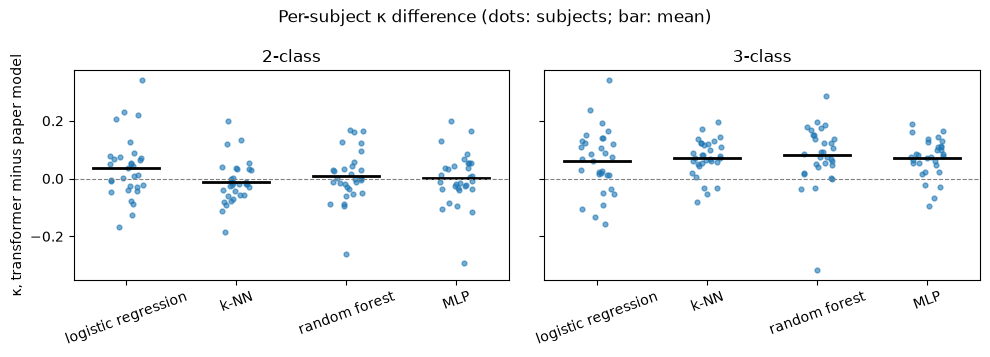

In [8]:
per = pd.read_csv(TABLES / "per_subject.csv", dtype={"subject": str})
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, n in zip(axes, [2, 3]):
    k = per.query("classes == @n").pivot(index="subject", columns="model", values="kappa")
    diffs = [k["transformer"] - k[m] for m in PAPER]
    rng = np.random.default_rng(0)
    for i, d in enumerate(diffs):
        ax.scatter(i + rng.uniform(-0.15, 0.15, len(d)), d, s=12, alpha=0.6, color="tab:blue")
        ax.plot([i - 0.3, i + 0.3], [d.mean()] * 2, color="black", lw=2)
    ax.axhline(0, color="grey", lw=0.8, ls="--")
    ax.set_xticks(range(4), [NAMES[m] for m in PAPER], rotation=20)
    ax.set_title(f"{n}-class")
axes[0].set_ylabel("κ, transformer minus paper model")
fig.suptitle("Per-subject κ difference (dots: subjects; bar: mean)")
fig.tight_layout()

- At 3 classes most dots sit above zero for every comparison: the gain is spread across
  subjects, not carried by a few nights.
- At 2 classes the differences straddle zero.

In [9]:
k3 = per.query("classes == 3").pivot(index="subject", columns="model", values="kappa")
print(f"3-class κ, transformer vs best paper model per subject: "
      f"higher in {(k3['transformer'] > k3[PAPER].max(axis=1)).sum()} of {len(k3)} nights")

3-class κ, transformer vs best paper model per subject: higher in 24 of 31 nights


## 5. Figures

Per-subject κ for every model and both tasks (written by `make eval`):

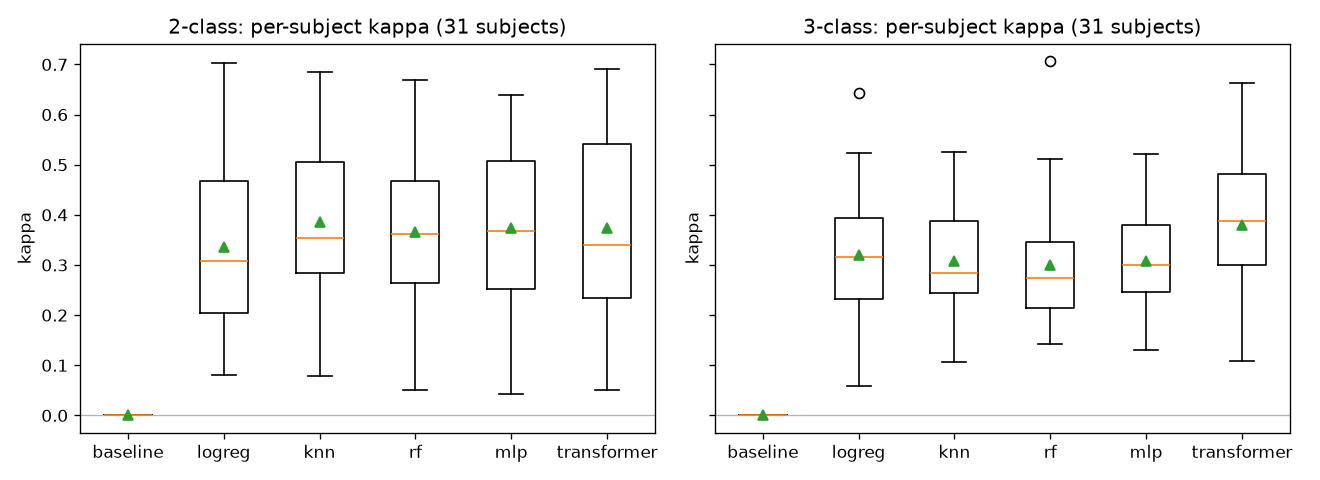

In [10]:
display(Image(FIGURES / "kappa_per_subject.png", width=800))

Row-normalised 3-class confusion matrix of the best 3-class model (the transformer),
averaged over subjects and seeds. NREM is the weakest class: about a quarter of NREM epochs
are called REM and a sixth wake:

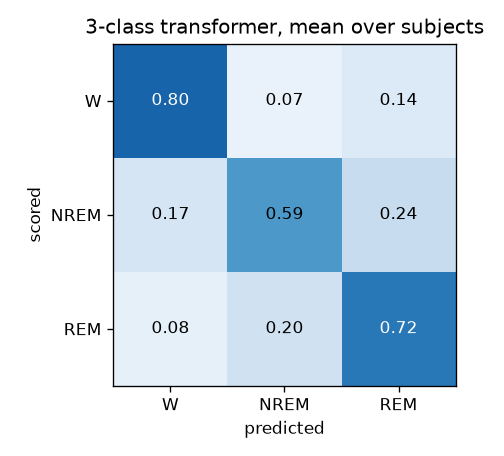

In [11]:
display(Image(FIGURES / "confusion_3class_best.png", width=420))

One night, scored vs MLP vs transformer (seed 0). The subject is the median by transformer κ
among nights with an NREM→REM transition, so it is a typical night, not a showcase. Both
models over-call wake in the first hour. The MLP calls REM through much of the second half of
the night; the transformer's REM sits on the one scored REM period.

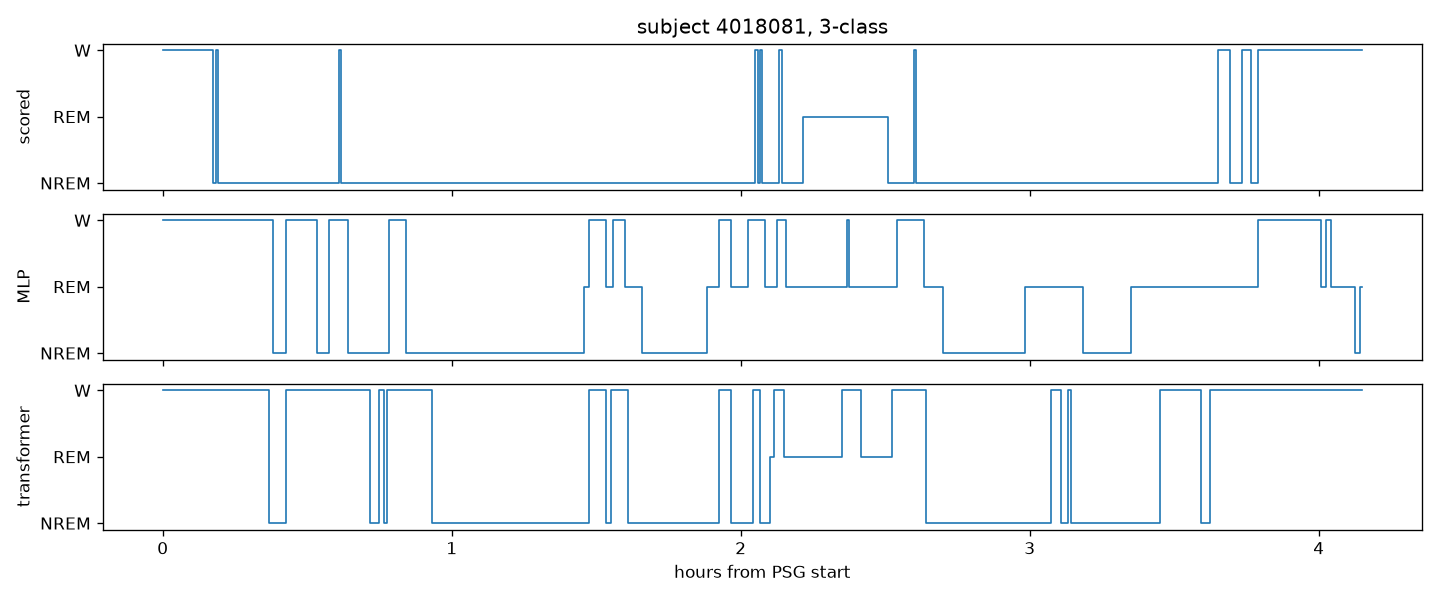

In [12]:
fig_night = sorted(FIGURES.glob("hypnogram_3class_*.png"))[0]
display(Image(fig_night, width=850))

Last-layer attention, averaged over heads, in the window around that night's first NREM→REM
transition. Attention is **not** concentrated around the transition; it falls on a few fixed
epochs of the window. This is one model on one window and does not explain the gain.

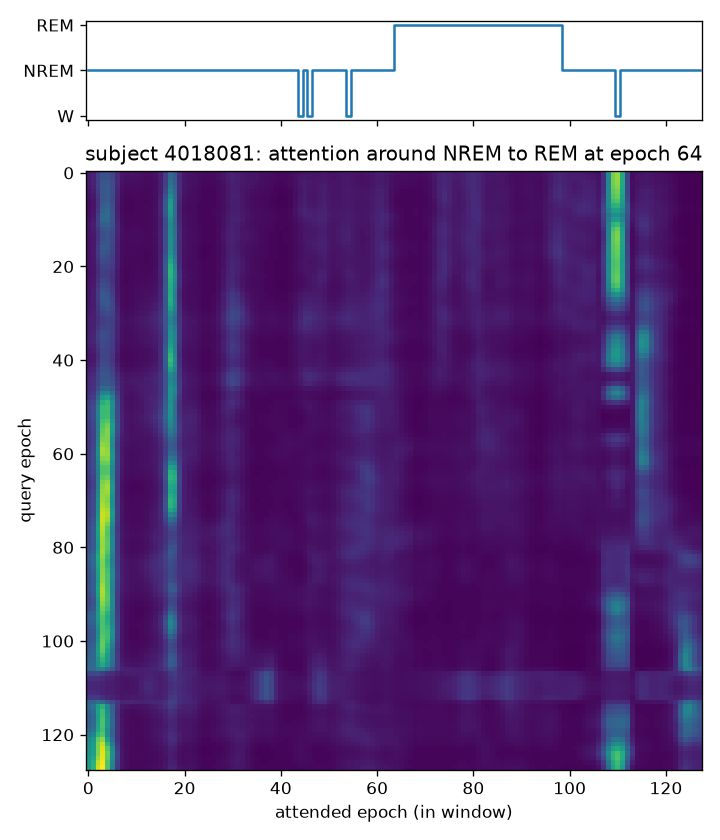

In [13]:
display(Image(sorted(FIGURES.glob("attention_3class_*.png"))[0], width=520))

## 6. What the transformer chose

Settings selected per outer fold by the inner-fold tuning:

In [14]:
tuning = pd.read_csv(TABLES / "tuning.csv").query("model == 'transformer'")
params = pd.DataFrame([eval(p) for p in tuning["params"]], index=tuning.index).assign(classes=tuning["classes"])
counts = params.astype(str).melt(id_vars="classes", var_name="setting").value_counts()
counts.unstack("classes", fill_value=0).add_prefix("folds, ").rename_axis(columns=None).sort_index()

folds, 2  folds, 3
setting value                     
d_model 32             8        14
        64            23        17
dropout 0.1           18        22
        0.3           13         9
lr      0.0003         4         3
        0.001         27        28
window  128           17        22
        32             4         7
        64            10         2

- The longest window, W = 128 epochs (64 minutes), was chosen in most folds. It is the edge of
  the grid, so longer context might help further. The grid was not widened after seeing the
  test results, because that would tune on them.

## 7. Conclusions and limitations

**Conclusions**
- Context helps where the per-epoch features are ambiguous. Telling NREM from REM is hard from
  one epoch's activity and HR variability, and easier from what surrounds it; that is where
  the transformer gains (3-class κ +0.06 to +0.08, paired CIs above zero).
- For wake versus sleep the per-epoch features already carry most of the signal; the
  transformer ranks epochs better (AUC) but its argmax predictions are no better.

**Limitations**
- **Gate:** one of the 12 gated reproduction rows misses the ±0.03 tolerance by 0.001.
- **Small sample:** 31 nights, one per person, from one lab; CIs are wide.
- **Offline scoring:** the smoothed features and the transformer both use later epochs, so this
  is whole-night scoring, not real-time staging.
- **Not separated:** whether the gain comes from context or from the transformer itself. A
  per-epoch model given the same window of neighbouring features would answer that.
- **Unequal training data:** the transformer trains on 27 of 30 training nights (3 are held out
  for early stopping); the paper models use all 30.
- **Clock proxy** differs from the paper's circadian model (see section 2).